In [1]:
import matplotlib.pyplot as plt
import numpy as np

from paper2026 import Osteostat
from paper2026 import get_time_vectors, get_default_initial_conditions, get_day_index
from paper2026 import configure_plotting_for_paper

In [2]:
figsize = configure_plotting_for_paper()

In [3]:
# Time-related parameters
n_years = 40
t_stop = n_years*365. # in days
t_inc = 0.2 # in days, timestep for solver

F0 = 0.12 # [kN] Initial force

f_bm0 = 0.85 # [-] initial bone volume fraction

solver='dopri5'

In [4]:
t_eval, t_force = get_time_vectors(t_stop=t_stop, t_inc=t_inc, t_inc_force=t_inc)
force = F0 * np.ones(t_force.size) 

In [5]:
ostat = Osteostat()

In [6]:
initial_condition = get_default_initial_conditions(ostat, F0, f_bm0)

### Increasing osteocyte apoptosis A by a factor of 2

To change attributes of the `Osteostat` object when solving the ODEs with `solve()`, we can pass a dictionary of events, where 
- the key is the time index when to apply the change and
- the value is a dictionary of attribute - new value pairs

For example, to double `A` after 5 years, `events={9125: {'A': 5.5321425e-05}}`, where `9125` is the index in the time vector corresponding to 5 years calculated with `get_day_index()`.

In [7]:
A_factor = 2 # double A
year_to_change = 5 # when to apply the change to A

similation_key_str = f"{A_factor:.1f} * A" # label for experiement in results

# construct events dictionary to double A at the 5 year point
events = {get_day_index(year_to_change*365, t_inc): {'A': A_factor * ostat.A}}

# solve the ODEs
ostat.solve(t_eval, initial_condition, force , t_force, similation_key_str, events=events, solver=solver)

using ode() with dopri5
 12%|██████▏                                           | 9011/73001 [00:04<00:33, 1911.25it/s]EVENT: (np.int64(9125), 'A', 5.5321425e-05)
EVENT: (np.int64(9125), 'A', 5.5321425e-05)
EVENT: (np.int64(9125), 'A', 5.5321425e-05)
EVENT: (np.int64(9125), 'A', 5.5321425e-05)
EVENT: (np.int64(9125), 'A', 5.5321425e-05)
EVENT: (np.int64(9125), 'A', 5.5321425e-05)
EVENT: (np.int64(9125), 'A', 5.5321425e-05)
100%|████████████████████████████████████████████████▉| 73000/73001 [00:37<00:00, 1967.84it/s]
Success
adding results with key 2.0 * A
100%|████████████████████████████████████████████████| 73001/73001 [00:05<00:00, 13285.12it/s]


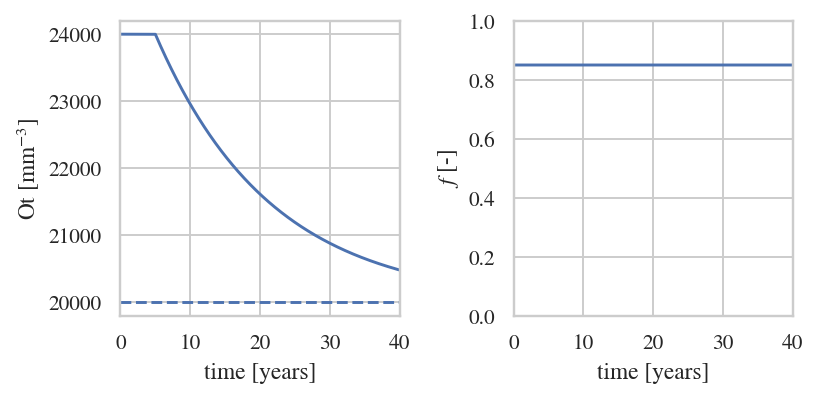

In [8]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6, 3))
axs = axs.flatten()
ostat.plot_result(similation_key_str, ['Ot', 'f_bm'], axs=axs, add_legend=False)

# calculate steady state Otbar for new A 
orig_A = ostat.A
ostat.A = A_factor * orig_A
otbar_steady_state = ostat.get_Ot_bar(f_bm0)
ostat.A = orig_A
axs[0].axhline(otbar_steady_state, linestyle="--")

axs[0].set_xlim([0, n_years])
axs[0].set_xlabel('time [years]')
axs[0].set_ylabel("Ot [mm$^{-3}$]")
axs[1].set_ylabel("$f$ [-]")
axs[1].set_xlim([0, n_years])
axs[1].set_xlabel('time [years]')
axs[1].set_ylim([0, 1])

plt.tight_layout()